##Name: Sanjana Bondre
##Roll no.: C2_28
##Project Title: Smart Waste Classification and Recommendation System
#Deep Learning Lab

In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices('GPU')) > 0)

print("Environment setup successful!")


TensorFlow version: 2.21.0
GPU available: True
Environment setup successful!


In [2]:

from google.colab import files

uploaded = files.upload()



Saving archive.zip to archive.zip


In [3]:

import zipfile
import os

zip_path = "/content/archive.zip"
extract_path = "/content/waste_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Files and folders found:")

for item in os.listdir(extract_path):
    print(item)


Dataset extracted successfully!
Files and folders found:
dataset-resized


In [4]:

import os

dataset_path = "/content/waste_dataset/dataset-resized"

print("Waste categories:\n")

for category in sorted(os.listdir(dataset_path)):
    category_path = os.path.join(dataset_path, category)

    if os.path.isdir(category_path):
        images = [
            f for f in os.listdir(category_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]
        print(f"{category}: {len(images)} images")

print("\nDataset inspection completed!")


Waste categories:

cardboard: 403 images
glass: 501 images
metal: 410 images
paper: 594 images
plastic: 482 images
trash: 137 images

Dataset inspection completed!


In [5]:

!pip -q install split-folders

import splitfolders

input_folder = "/content/waste_dataset/dataset-resized"
output_folder = "/content/waste_split"

splitfolders.ratio(
    input_folder,
    output=output_folder,
    seed=42,
    ratio=(0.70, 0.15, 0.15)
)

print("Dataset split completed!")


Copying files: 2527 files [00:00, 7121.28 files/s]

Dataset split completed!


In [6]:

import tensorflow as tf

# Dataset folders
train_dir = "/content/waste_split/train"
val_dir = "/content/waste_split/val"
test_dir = "/content/waste_split/test"

# Image settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Load training images
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED
)

# Load validation images
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Load testing images
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names

print("\nWaste categories:", class_names)
print("Number of categories:", len(class_names))
print("\nImage datasets loaded successfully!")


Found 1766 files belonging to 6 classes.
Found 377 files belonging to 6 classes.
Found 384 files belonging to 6 classes.

Waste categories: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Number of categories: 6

Image datasets loaded successfully!


In [7]:

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers initially
base_model.trainable = False

# Build our waste classification model
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(6, activation="softmax")
])

# Configure model training
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [8]:

# Train the model
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

print("Training completed!")


Epoch 1/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 26s 250ms/step - accuracy: 0.5578 - loss: 1.1856 - val_accuracy: 0.7374 - val_loss: 0.7334
Epoch 2/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.7599 - loss: 0.6441 - val_accuracy: 0.7984 - val_loss: 0.5736
Epoch 3/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.8222 - loss: 0.5078 - val_accuracy: 0.8223 - val_loss: 0.5216
Epoch 4/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.8471 - loss: 0.4501 - val_accuracy: 0.8329 - val_loss: 0.4842
Epoch 5/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.8783 - loss: 0.3712 - val_accuracy: 0.8435 - val_loss: 0.4688
Epoch 6/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.8805 - loss: 0.3445 - val_accuracy: 0.8408 - val_loss: 0.4534
Epoch 7/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.8998 - loss: 0.3051 - val_accuracy: 0.8515 - val_loss: 0.4451
Epoch 8/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.8986 - loss: 0.2864 - val_accuracy: 0.8674 -

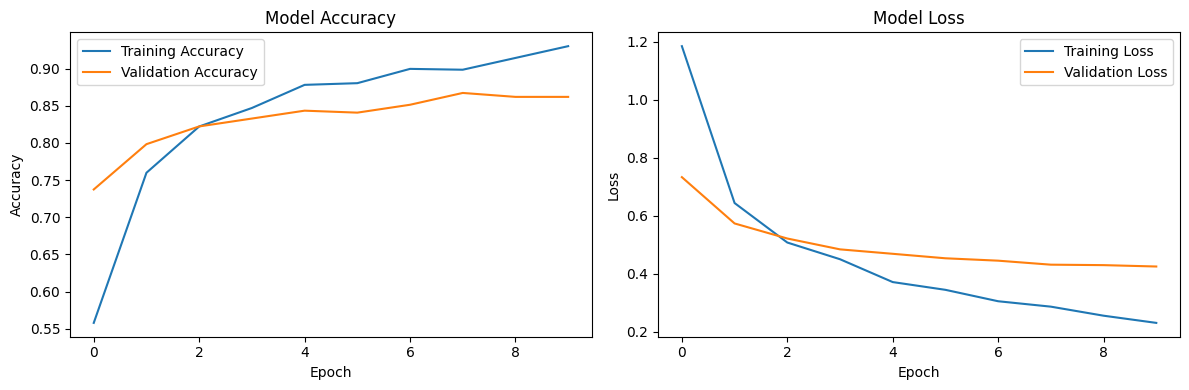

In [9]:

import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [10]:

test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.8203 - loss: 0.4837
Test Loss: 0.4837
Test Accuracy: 82.03%


12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step
              precision    recall  f1-score   support

   cardboard       0.96      0.84      0.89        61
       glass       0.83      0.68      0.75        76
       metal       0.84      0.84      0.84        62
       paper       0.85      0.89      0.87        90
     plastic       0.70      0.85      0.77        73
       trash       0.75      0.82      0.78        22

    accuracy                           0.82       384
   macro avg       0.82      0.82      0.82       384
weighted avg       0.83      0.82      0.82       384



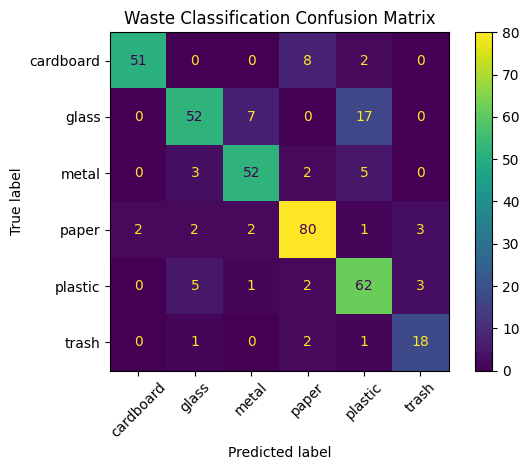

In [11]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Actual labels
y_true = np.concatenate([labels.numpy() for images, labels in test_ds])

# Predicted labels
predictions = model.predict(test_ds)
y_pred = np.argmax(predictions, axis=1)

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
display.plot(xticks_rotation=45)
plt.title("Waste Classification Confusion Matrix")
plt.tight_layout()
plt.show()


In [12]:

model.save("/content/waste_classifier_stage1.keras")
print("Stage 1 model saved successfully!")


Stage 1 model saved successfully!


In [13]:

# Unfreeze the MobileNetV2 base model
base_model.trainable = True

# Keep most layers frozen; train only the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stability
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a very small learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))
print("Fine-tuning setup completed!")


Trainable layers: 19
Fine-tuning setup completed!


In [14]:

fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

print("Fine-tuning completed!")


Epoch 1/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 26s 228ms/step - accuracy: 0.9253 - loss: 0.2141 - val_accuracy: 0.8753 - val_loss: 0.4010
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.9451 - loss: 0.1685 - val_accuracy: 0.8700 - val_loss: 0.4025
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.9638 - loss: 0.1299 - val_accuracy: 0.8727 - val_loss: 0.3938
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.9717 - loss: 0.1138 - val_accuracy: 0.8727 - val_loss: 0.3869
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - accuracy: 0.9751 - loss: 0.0993 - val_accuracy: 0.8727 - val_loss: 0.3889
Fine-tuning completed!


In [15]:

fine_loss, fine_accuracy = model.evaluate(test_ds)

print(f"Stage 2 Test Accuracy: {fine_accuracy * 100:.2f}%")


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.8307 - loss: 0.4826
Stage 2 Test Accuracy: 83.07%


In [16]:

# Record the results from both stages
stage1_accuracy = 82.00  # From your Stage 1 classification report
stage2_accuracy = fine_accuracy * 100

print("MODEL PERFORMANCE COMPARISON")
print("-" * 35)
print(f"Stage 1 Test Accuracy: {stage1_accuracy:.2f}%")
print(f"Stage 2 Test Accuracy: {stage2_accuracy:.2f}%")
print(f"Difference: {stage2_accuracy - stage1_accuracy:+.2f} percentage points")

# Save the fine-tuned model
model.save("/content/waste_classifier_final.keras")
print("\nFinal model saved successfully!")


MODEL PERFORMANCE COMPARISON
-----------------------------------
Stage 1 Test Accuracy: 82.00%
Stage 2 Test Accuracy: 83.07%
Difference: +1.07 percentage points

Final model saved successfully!


Saving Screenshot 2026-10-21 191336.png to Screenshot 2026-10-21 191336.png


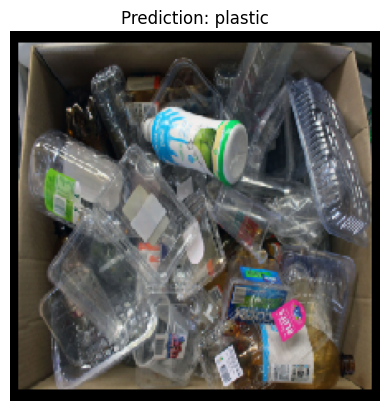

Predicted category: plastic
Confidence: 99.87%


In [17]:

from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

# Upload an image
uploaded = files.upload()

# Get the uploaded filename
image_path = next(iter(uploaded))

# Load and prepare the image
img = load_img(image_path, target_size=(224, 224))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict the waste category
predictions = model.predict(img_array, verbose=0)[0]
predicted_index = np.argmax(predictions)
predicted_class = class_names[predicted_index]
confidence = predictions[predicted_index] * 100

# Display result
plt.imshow(img)
plt.axis("off")
plt.title(f"Prediction: {predicted_class}")
plt.show()

print("Predicted category:", predicted_class)
print(f"Confidence: {confidence:.2f}%")


In [18]:

# Disposal guidance for each waste category
disposal_guidance = {
    "cardboard": "Keep dry and clean. Flatten boxes and place them in paper/cardboard recycling.",
    "glass": "Separate by local recycling rules. Handle broken glass carefully.",
    "metal": "Empty cans and containers, then place them in metal recycling where accepted.",
    "paper": "Keep paper clean and dry. Separate contaminated paper from recyclable paper.",
    "plastic": "Empty containers and check local recycling rules. Rinse when required.",
    "trash": "Place in the appropriate residual-waste bin. Check local rules for special disposal."
}

print("SMART WASTE CLASSIFICATION RESULT")
print("-" * 35)
print("Predicted category:", predicted_class)
print(f"Confidence: {confidence:.2f}%")
print("\nRecommended action:")
print(disposal_guidance[predicted_class])


SMART WASTE CLASSIFICATION RESULT
-----------------------------------
Predicted category: plastic
Confidence: 99.87%

Recommended action:
Empty containers and check local recycling rules. Rinse when required.


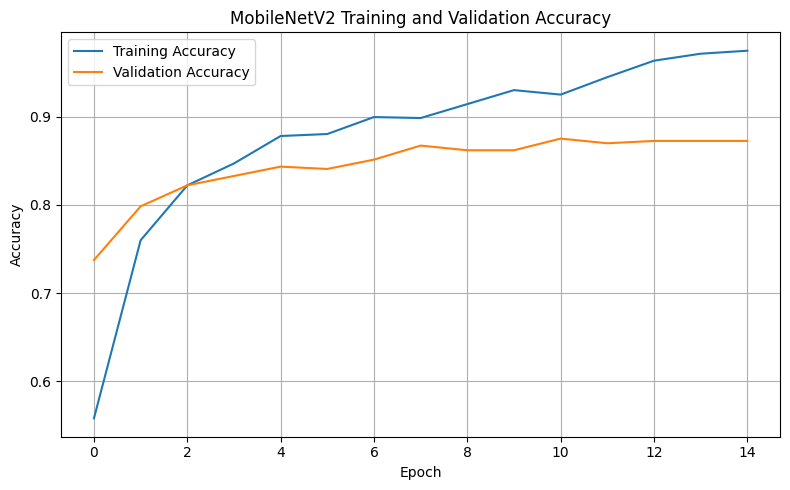

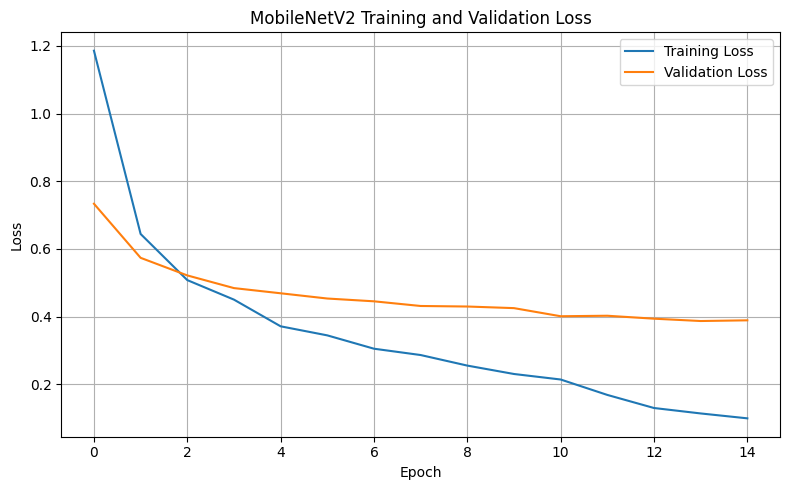

Both evaluation graphs saved!


In [19]:

import matplotlib.pyplot as plt

# Combine histories from both training stages
train_acc = (
    history.history["accuracy"]
    + fine_tune_history.history["accuracy"]
)
val_acc = (
    history.history["val_accuracy"]
    + fine_tune_history.history["val_accuracy"]
)
train_loss = (
    history.history["loss"]
    + fine_tune_history.history["loss"]
)
val_loss = (
    history.history["val_loss"]
    + fine_tune_history.history["val_loss"]
)

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(train_acc, label="Training Accuracy")
plt.plot(val_acc, label="Validation Accuracy")
plt.title("MobileNetV2 Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/accuracy_graph.png", dpi=300)
plt.show()

# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.title("MobileNetV2 Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/loss_graph.png", dpi=300)
plt.show()

print("Both evaluation graphs saved!")


In [20]:

!pip -q install gradio


In [22]:

import gradio as gr
import numpy as np
import html
from tensorflow.keras.utils import img_to_array

disposal_guidance = {
    "cardboard": "Keep dry and flatten boxes before recycling.",
    "glass": "Handle carefully and follow local glass recycling rules.",
    "metal": "Empty containers and recycle where accepted.",
    "paper": "Keep paper clean and dry for recycling.",
    "plastic": "Empty containers and check local recycling rules.",
    "trash": "Place in residual waste and check local disposal rules."
}

def classify_waste(image):
    if image is None:
        return None, {}, """
        <div class="result-card">
            <h2>🌱 Ready to make a difference?</h2>
            <p>Upload a waste image to discover its category.</p>
        </div>
        """

    # Prepare image for MobileNetV2
    image = image.convert("RGB")
    resized = image.resize((224, 224))
    arr = img_to_array(resized)
    arr = np.expand_dims(arr, axis=0)

    # Predict
    predictions = model.predict(arr, verbose=0)[0]
    idx = int(np.argmax(predictions))
    category = class_names[idx]
    confidence = float(predictions[idx]) * 100

    scores = {
        class_names[i]: float(predictions[i])
        for i in range(len(class_names))
    }

    guidance = disposal_guidance[category]

    # Escape text before inserting it into HTML
    safe_category = html.escape(category.title())
    safe_guidance = html.escape(guidance)

    result_html = f"""
    <div class="result-card">
        <div class="result-kicker">YOUR CLASSIFICATION RESULT</div>
        <div class="result-category">♻️ {safe_category}</div>
        <div class="confidence-label">
            Model confidence: <strong>{confidence:.2f}%</strong>
        </div>
        <div class="confidence-track">
            <div class="confidence-fill"
                 style="width: {confidence:.2f}%"></div>
        </div>
        <div class="tip-box">
            <div class="tip-heading">🌿 Give this waste a better next life</div>
            <p>{safe_guidance}</p>
        </div>
    </div>
    """

    return image, scores, result_html


custom_css = """
.gradio-container {
    max-width: 1100px !important;
    margin: auto !important;
    background: #f5f6ee !important;
    color: #203d30 !important;
    font-family: Arial, sans-serif !important;
}
#eco-hero {
    background: linear-gradient(120deg, #173f35, #347653);
    border-radius: 22px;
    padding: 30px;
    color: #ffffff;
    margin-bottom: 18px;
}
#eco-hero h1 {
    color: #ffffff !important;
    font-size: 34px !important;
    margin-bottom: 8px !important;
}
#eco-hero p { color: #e1f0df !important; }
#eco-hero .hero-tag {
    color: #d9edbd;
    text-transform: uppercase;
    letter-spacing: 2px;
    font-size: 12px;
    font-weight: bold;
}
.eco-panel {
    background: #ffffff;
    border: 1px solid #e0e7d9;
    border-radius: 18px;
    padding: 16px;
}
.result-card {
    background: #ffffff;
    border: 1px solid #dbe6d6;
    border-radius: 18px;
    padding: 24px;
    color: #203d30;
    min-height: 210px;
}
.result-kicker {
    color: #64806a;
    font-size: 11px;
    font-weight: bold;
    letter-spacing: 1.5px;
}
.result-category {
    color: #215b3d;
    font-size: 34px;
    font-weight: 800;
    margin: 16px 0 8px;
}
.confidence-label {
    color: #526b58;
    font-size: 14px;
    margin-bottom: 10px;
}
.confidence-track {
    height: 9px;
    background: #e8eee3;
    border-radius: 10px;
    overflow: hidden;
}
.confidence-fill {
    height: 9px;
    background: #4d9564;
    border-radius: 10px;
}
.tip-box {
    background: #f0f5e9;
    border-radius: 12px;
    padding: 15px;
    margin-top: 22px;
}
.tip-heading {
    color: #28583c;
    font-weight: bold;
    margin-bottom: 7px;
}
.tip-box p {
    color: #455e4a;
    margin: 0;
    line-height: 1.6;
}
#eco-footer {
    text-align: center;
    color: #6c806d;
    padding: 16px;
    font-size: 12px;
}
"""

with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="green",
        secondary_hue="lime",
        neutral_hue="stone"
    ),
    css=custom_css,
    title="EcoSort | Smart Waste Classification"
) as demo:

    gr.HTML("""
    <div id="eco-hero">
        <div class="hero-tag">♻ Sustainable living starts here</div>
        <h1>🌿 EcoSort</h1>
        <p>
            Turn waste into the right next step.
            Identify waste with AI and discover how to dispose of it responsibly.
        </p>
    </div>
    """)

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("### 📷 01 · Upload your waste")
            input_image = gr.Image(
                type="pil",
                label="Choose an image",
                height=300
            )
            classify_button = gr.Button(
                "♻ Classify Waste",
                variant="primary",
                size="lg"
            )
            gr.Markdown(
                "Supported categories: cardboard, glass, metal, "
                "paper, plastic and trash."
            )

        with gr.Column(scale=1):
            gr.Markdown("### 🌱 02 · Your results")
            output_html = gr.HTML("""
            <div class="result-card">
                <div class="result-kicker">YOUR CLASSIFICATION RESULT</div>
                <div class="result-category">🌎 EcoSort is ready</div>
                <p>Upload an image and click Classify Waste to see the result.</p>
            </div>
            """)
            output_scores = gr.Label(
                num_top_classes=6,
                label="Prediction scores"
            )

    classify_button.click(
        fn=classify_waste,
        inputs=input_image,
        outputs=[input_image, output_scores, output_html]
    )

    gr.Markdown("""
    ### 🌍 About EcoSort
    EcoSort uses **MobileNetV2 transfer learning** to classify images
    into six waste categories. It provides a suggested disposal action
    to support more responsible waste management.

    Predictions are estimates. Follow your local recycling and disposal rules.
    """)

    gr.HTML("""
    <div id="eco-footer">
        Made for a greener tomorrow · Smart Waste Classification Project
    </div>
    """)

demo.launch(share=True)


/tmp/ipykernel_677/2845402340.py:162: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0d0b92879c2354b229.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
